# Land Acquisition Delay — Risk Model

End-to-end pipeline: EDA → leakage-safe feature set → model training/comparison → SHAP explainability → geographic risk aggregation → what-if simulation → deployable API output.

**Cleanup notes (from the original 148-cell notebook):**
- Removed duplicate/dead cells (repeated imports, empty cells, re-run EDA, three different attempts at the same choropleth map).
- `categorical_cols`/`numerical_cols` are now computed once by a single helper instead of being redetected ~6 times with patchwork fixes for `ownership_complexity`.
- Model training/threshold-tuning/evaluation logic was duplicated per-model (Logistic/RF/XGB) — factored into shared functions.
- The model comparison table previously hardcoded the Logistic Regression numbers from an earlier run; it now reads results from the same run that produced RF/XGB.
- Fixed a broken cell that referenced undefined variables (`feature_level_df`, `original_case`) — replaced with a single working per-case SHAP explanation function.
- District-risk aggregation was built three times with slightly different logic (raw probability vs. percentage); consolidated into one version.
- Translated a Hindi/English-mixed comment.
- Kept only the final, working choropleth (Plotly) and a static overview map (Matplotlib); dropped the intermediate failed attempts.


## 1. Setup

In [2]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

import shap
import joblib

pd.set_option("display.max_rows", 100)
RANDOM_STATE = 42


C:\Users\MD ZAID\anaconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Data

In [3]:
df = pd.read_csv("training_dataset.csv")
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (46372, 94)


,case_snapshot_id,acquisition_case_id,project_id,parcel_id,prediction_date,prediction_window_days,project_type,state,district,tehsil,...,prototype_risk_probability,prototype_risk_category,prototype_risk_confidence,information_availability_date,observation_type,risk_score_type,model_source,model_version,target_consistent,snapshot_origin
0,CASE-00001_ASOF_20251025_CASE_START,CASE-00001,PROJ-0001,PARCEL-00001,2025-10-25,45,Canal,Maharashtra,Pune,Haveli,...,0.351471,MEDIUM,0.633676,2025-10-25,EARLY_WARNING,synthetic_prototype_score,prototype_formula,v1.3.2-proto-1,True,SYNTHETIC_TEMPORAL_AUGMENTATION
1,CASE-00001_ASOF_20251109_FOLLOW_UP_DAY_15,CASE-00001,PROJ-0001,PARCEL-00001,2025-11-09,30,Canal,Maharashtra,Pune,Haveli,...,0.475925,MEDIUM,0.521668,2025-11-09,EARLY_WARNING,synthetic_prototype_score,prototype_formula,v1.3.2-proto-1,True,SYNTHETIC_TEMPORAL_AUGMENTATION
2,CASE-00001-S01,CASE-00001,PROJ-0001,PARCEL-00001,2025-11-18,60,Canal,Maharashtra,Pune,Haveli,...,0.349244,MEDIUM,0.635680,2025-11-18,EARLY_WARNING,synthetic_prototype_score,prototype_formula,v1.3.2-proto-1,True,BASELINE_V1.3.1
3,CASE-00001_ASOF_20251124_FOLLOW_UP_DAY_30,CASE-00001,PROJ-0001,PARCEL-00001,2025-11-24,15,Canal,Maharashtra,Pune,Haveli,...,0.639983,HIGH,0.625985,2025-11-24,EARLY_WARNING,synthetic_prototype_score,prototype_formula,v1.3.2-proto-1,True,SYNTHETIC_TEMPORAL_AUGMENTATION
4,CASE-00001-S02,CASE-00001,PROJ-0001,PARCEL-00001,2026-03-20,30,Canal,Maharashtra,Pune,Haveli,...,0.599101,HIGH,0.589191,2026-03-20,MONITORING,synthetic_prototype_score,prototype_formula,v1.3.2-proto-1,True,BASELINE_V1.3.1


## 3. Exploratory Data Analysis

In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 46372 entries, 0 to 46371
Data columns (total 94 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   case_snapshot_id                         46372 non-null  str    
 1   acquisition_case_id                      46372 non-null  str    
 2   project_id                               46372 non-null  str    
 3   parcel_id                                46372 non-null  str    
 4   prediction_date                          46372 non-null  str    
 5   prediction_window_days                   46372 non-null  int64  
 6   project_type                             46372 non-null  str    
 7   state                                    46372 non-null  str    
 8   district                                 46372 non-null  str    
 9   tehsil                                   46372 non-null  str    
 10  required_land_area_acres                 46372 non-null  

In [5]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
case_snapshot_id,46372,46372,CASE-00001_ASOF_20251025_CASE_START,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
acquisition_case_id,46372,10000,CASE-00004,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
project_id,46372,300,PROJ-0059,171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parcel_id,46372,10000,PARCEL-00004,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
prediction_date,46372,1654,2026-08-15,184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
prediction_window_days,46372.0,NaN,NaN,NaN,68.713016,50.381016,15.0,30.0,45.0,90.0,180.0
project_type,46372,9,Highway,16977,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,46372,5,Maharashtra,11402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
district,46372,25,Solapur,1927,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tehsil,46372,25,Hingna,1927,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
def missing_value_report(frame):
    """Missing-value count/percentage per column, sorted worst-first."""
    report = pd.DataFrame({
        "missing_count": frame.isna().sum(),
        "missing_percentage": frame.isna().mean() * 100,
    })
    return report.sort_values("missing_percentage", ascending=False)

missing_value_report(df).head(20)


,missing_count,missing_percentage
intersection_percentage,5749,12.397567
case_snapshot_id,0,0.000000
post_outcome_observation,0,0.000000
target_threshold_date,0,0.000000
project_start_date,0,0.000000
land_context_provenance,0,0.000000
dataset_split,0,0.000000
data_source_type,0,0.000000
delay_days,0,0.000000
acquisition_delayed,0,0.000000


In [7]:
def column_audit(frame):
    """One-row-per-column summary: dtype, missingness, cardinality."""
    return pd.DataFrame({
        "column": frame.columns,
        "dtype": frame.dtypes.astype(str).values,
        "missing_count": frame.isna().sum().values,
        "missing_percentage": (frame.isna().mean() * 100).values,
        "unique_values": frame.nunique().values,
    })

column_audit(df)


,column,dtype,missing_count,missing_percentage,unique_values
0,case_snapshot_id,str,0,0.000000,46372
1,acquisition_case_id,str,0,0.000000,10000
2,project_id,str,0,0.000000,300
3,parcel_id,str,0,0.000000,10000
4,prediction_date,str,0,0.000000,1654
5,prediction_window_days,int64,0,0.000000,6
6,project_type,str,0,0.000000,9
7,state,str,0,0.000000,5
8,district,str,0,0.000000,25
9,tehsil,str,0,0.000000,25


In [8]:
# `intersection_percentage` is almost entirely missing / not usable as a
# feature — check before deciding whether to drop it.
print(df["intersection_percentage"].describe())
print("Missing:", df["intersection_percentage"].isna().sum())
print(df[["intersection_percentage", "acquisition_delayed"]].corr())


count    40623.000000
mean        52.950739
std         27.421110
min          5.000000
25%         29.365000
50%         53.380000
75%         76.560000
max        100.000000
Name: intersection_percentage, dtype: float64
Missing: 5749
                         intersection_percentage  acquisition_delayed
intersection_percentage                 1.000000             0.004197
acquisition_delayed                     0.004197             1.000000


In [9]:
df = df.drop(columns=["intersection_percentage"])


In [10]:
# Columns naming risk/model/prototype fields — worth knowing they exist so
# they aren't accidentally left in the feature set (see leakage list below).
risk_cols = [
    col for col in df.columns
    if any(word in col.lower() for word in ["risk", "prototype", "model"])
]
print(risk_cols)
df[risk_cols].nunique()


['prototype_risk_probability', 'prototype_risk_category', 'prototype_risk_confidence', 'risk_score_type', 'model_source', 'model_version']


prototype_risk_probability    46372
prototype_risk_category           4
prototype_risk_confidence     46372
risk_score_type                   1
model_source                      1
model_version                     1
dtype: int64

## 4. Leakage-Safe Feature Set

In [11]:
# Keep only rows eligible for the early-warning prediction task.
model_df = df[df["prediction_eligible"] == 1].copy()
print("Early-warning dataset shape:", model_df.shape)


Early-warning dataset shape: (23283, 93)


In [12]:
COLUMNS_TO_REMOVE = [
    # IDs
    "case_snapshot_id",
    "acquisition_case_id",
    "project_id",
    "parcel_id",

    # Targets
    "acquisition_delayed",
    "delay_days",

    # Existing prototype/model outputs — DATA LEAKAGE
    "prototype_risk_probability",
    "prototype_risk_category",
    "prototype_risk_confidence",
    "risk_score_type",
    "model_source",
    "model_version",

    # Post-outcome / future information
    "post_threshold_observation",
    "post_outcome_observation",
    "target_threshold_date",
    "information_availability_date",

    # Dataset metadata
    "dataset_split",
    "data_source_type",
    "land_context_provenance",
    "observation_type",
    "prediction_eligible",
    "target_consistent",
    "snapshot_origin",
]

model_df = model_df.drop(columns=COLUMNS_TO_REMOVE)
print("Shape after removing leakage/metadata:", model_df.shape)
print("Final feature count:", model_df.shape[1])


Shape after removing leakage/metadata: (23283, 70)
Final feature count: 70


In [13]:
X = model_df.copy()
y = df.loc[X.index, "acquisition_delayed"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print(y.value_counts(normalize=True).mul(100).round(2))


X shape: (23283, 70)
y shape: (23283,)
acquisition_delayed
0    58.92
1    41.08
Name: proportion, dtype: float64


## 5. Feature Engineering

In [14]:
def add_date_parts(frame, date_col, prefix, drop_original=True, errors="raise"):
    """Expand a date column into year/month/quarter features."""
    parsed = pd.to_datetime(frame[date_col], errors=errors)
    frame[f"{prefix}_year"] = parsed.dt.year
    frame[f"{prefix}_month"] = parsed.dt.month
    frame[f"{prefix}_quarter"] = parsed.dt.quarter
    if drop_original:
        frame = frame.drop(columns=[date_col])
    return frame

X = add_date_parts(X, "prediction_date", "prediction")
X = add_date_parts(X, "project_start_date", "project_start", errors="coerce")

# `ownership_complexity` arrives as an object dtype despite being a numeric
# score — cast it once here instead of patching the categorical/numerical
# column lists after the fact.
X["ownership_complexity"] = pd.to_numeric(
    X["ownership_complexity"], errors="coerce"
)

print("Features:", X.shape)


Features: (23283, 74)


In [15]:
def get_column_types(frame):
    """Single source of truth for categorical vs. numerical columns."""
    categorical = frame.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()
    numerical = frame.select_dtypes(include=["number"]).columns.tolist()
    return categorical, numerical

categorical_cols, numerical_cols = get_column_types(X)
print("Categorical columns:", len(categorical_cols))
print("Numerical columns:", len(numerical_cols))


Categorical columns: 16
Numerical columns: 58


C:\Users\MD ZAID\AppData\Local\Temp\ipykernel_19712\2069316273.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = frame.select_dtypes(


In [16]:
missing = X.isna().sum()
missing[missing > 0].sort_values(ascending=False)


ownership_complexity    4757
dtype: int64

## 6. Train / Validation / Test Split

In [17]:
split = df.loc[X.index, "dataset_split"]

X_train, y_train = X[split == "TRAIN"].copy(), y[split == "TRAIN"].copy()
X_val, y_val = X[split == "VALIDATION"].copy(), y[split == "VALIDATION"].copy()
X_test, y_test = X[split == "TEST"].copy(), y[split == "TEST"].copy()

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

# Column types are derived from the training split (guards against a
# category showing up only in val/test).
categorical_cols, numerical_cols = get_column_types(X_train)


Train: (16318, 74) (16318,)
Validation: (3498, 74) (3498,)
Test: (3467, 74) (3467,)


C:\Users\MD ZAID\AppData\Local\Temp\ipykernel_19712\2069316273.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = frame.select_dtypes(


## 7. Preprocessing Pipeline

In [18]:
def build_preprocessor(numerical_cols, categorical_cols):
    numeric_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
    ])

    return ColumnTransformer([
        ("num", numeric_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols),
    ])

preprocessor = build_preprocessor(numerical_cols, categorical_cols)


## 8. Model Training, Threshold Tuning & Evaluation

Shared helpers so each model (Logistic Regression, Random Forest, XGBoost) goes through exactly the same fit → tune-threshold → test-evaluate steps.

In [19]:
def evaluate(y_true, y_pred, y_prob, label=""):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
    }
    if label:
        print(f"===== {label} =====")
        for name, value in metrics.items():
            print(f"{name:>10}: {value:.4f}")
        print("\nConfusion Matrix:")
        print(confusion_matrix(y_true, y_pred))
    return metrics


def find_best_threshold(y_true, y_prob, thresholds=np.arange(0.20, 0.71, 0.01)):
    """Sweep thresholds on validation probabilities, pick the best F1."""
    rows = []
    for threshold in thresholds:
        pred = (y_prob >= threshold).astype(int)
        rows.append({
            "threshold": threshold,
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
        })
    results = pd.DataFrame(rows)
    return results.loc[results["f1"].idxmax()]


def train_tune_evaluate(name, classifier, preprocessor,
                         X_train, y_train, X_val, y_val, X_test, y_test):
    """Fit a pipeline, pick its best threshold on validation, score on test."""
    pipeline = Pipeline([("preprocessor", preprocessor), ("classifier", classifier)])
    pipeline.fit(X_train, y_train)

    val_prob = pipeline.predict_proba(X_val)[:, 1]
    best = find_best_threshold(y_val, val_prob)
    threshold = best["threshold"]

    test_prob = pipeline.predict_proba(X_test)[:, 1]
    test_pred = (test_prob >= threshold).astype(int)
    metrics = evaluate(y_test, test_pred, test_prob, label=f"{name} — TEST")
    metrics["threshold"] = threshold

    return {
        "pipeline": pipeline,
        "threshold": threshold,
        "test_probabilities": test_prob,
        "metrics": metrics,
    }


In [20]:
models = {}

models["Logistic Regression"] = train_tune_evaluate(
    "Logistic Regression",
    LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
    preprocessor, X_train, y_train, X_val, y_val, X_test, y_test,
)


===== Logistic Regression — TEST =====
  accuracy: 0.6643
 precision: 0.5870
    recall: 0.7278
        f1: 0.6498
   roc_auc: 0.7467

Confusion Matrix:
[[1223  760]
 [ 404 1080]]


In [21]:
models["Random Forest"] = train_tune_evaluate(
    "Random Forest",
    RandomForestClassifier(
        n_estimators=300, min_samples_split=5, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1,
    ),
    preprocessor, X_train, y_train, X_val, y_val, X_test, y_test,
)


===== Random Forest — TEST =====
  accuracy: 0.6418
 precision: 0.5604
    recall: 0.7561
        f1: 0.6437
   roc_auc: 0.7258

Confusion Matrix:
[[1103  880]
 [ 362 1122]]


In [22]:
models["XGBoost"] = train_tune_evaluate(
    "XGBoost",
    XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        objective="binary:logistic", eval_metric="logloss",
        random_state=RANDOM_STATE, n_jobs=-1,
    ),
    preprocessor, X_train, y_train, X_val, y_val, X_test, y_test,
)


===== XGBoost — TEST =====
  accuracy: 0.6547
 precision: 0.5769
    recall: 0.7257
        f1: 0.6428
   roc_auc: 0.7337

Confusion Matrix:
[[1193  790]
 [ 407 1077]]


In [23]:
comparison = pd.DataFrame([
    {"model": name, **result["metrics"]}
    for name, result in models.items()
]).sort_values("roc_auc", ascending=False)

comparison


,model,accuracy,precision,recall,f1,roc_auc,threshold
0,Logistic Regression,0.664263,0.586957,0.727763,0.649819,0.746727,0.36
2,XGBoost,0.654745,0.576861,0.725741,0.642793,0.733658,0.35
1,Random Forest,0.641765,0.560440,0.756065,0.643718,0.725843,0.36


In [24]:
# XGBoost is the production candidate used for the rest of the notebook.
best_name = comparison.iloc[0]["model"]
xgb_result = models["XGBoost"]
xgb_model = xgb_result["pipeline"]
xgb_best_threshold = xgb_result["threshold"]
xgb_test_prob = xgb_result["test_probabilities"]

xgb_preprocessor = xgb_model.named_steps["preprocessor"]
xgb_classifier = xgb_model.named_steps["classifier"]
feature_names = xgb_preprocessor.get_feature_names_out()


## 9. SHAP Explainability (XGBoost)

In [25]:
X_test_transformed = xgb_preprocessor.transform(X_test)
explainer = shap.TreeExplainer(xgb_classifier)
shap_values = explainer.shap_values(X_test_transformed)
print("SHAP values computed:", shap_values.shape)


SHAP values computed: (3467, 199)


In [26]:
FEATURE_DISPLAY_NAMES = {
    "project_type": "Project Type",
    "state": "State",
    "district": "District",
    "tehsil": "Tehsil",
    "land_use": "Land Use",
    "ownership_type": "Ownership Type",
    "joint_ownership": "Joint Ownership",
    "gis_available": "GIS Available",
    "mutation_status": "Mutation Status",
    "ownership_complexity": "Ownership Complexity",
    "compensation_status": "Compensation Status",
    "dispute_type": "Dispute Type",
    "legal_stage": "Legal Stage",
    "rr_assessment_status": "R&R Assessment Status",
    "entitlement_status": "Entitlement Status",
    "rehabilitation_status": "Rehabilitation Status",
    "rr_payment_status": "R&R Payment Status",
}


def clean_feature_name(name):
    """Turn a one-hot-encoded pipeline name into a human-readable label."""
    name = name.replace("cat__", "").replace("num__", "")

    for feature, display in FEATURE_DISPLAY_NAMES.items():
        if name.startswith(feature + "_"):
            value = name[len(feature) + 1:]
            value = {"True": "Yes", "False": "No"}.get(value, value)
            return f"{display}: {value}"

    return name.replace("_", " ").title()


clean_feature_names = [clean_feature_name(name) for name in feature_names]


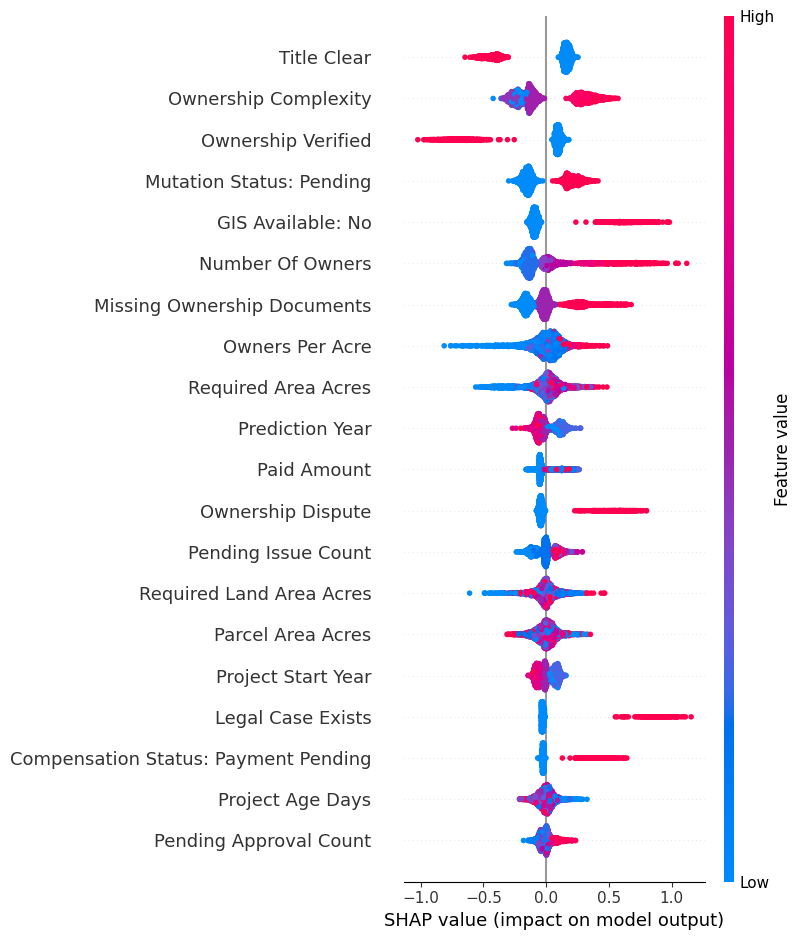

In [27]:
shap.summary_plot(
    shap_values, X_test_transformed,
    feature_names=clean_feature_names, max_display=20,
)


In [28]:
def explain_case(case_X, xgb_model, xgb_preprocessor, explainer, feature_names,
                  categorical_cols, top_n=5):
    """SHAP breakdown for a single case, aggregated back to original columns."""
    transformed = xgb_preprocessor.transform(case_X)
    case_shap = explainer.shap_values(transformed)[0]

    rows = []
    for feature, value in zip(feature_names, case_shap):
        if feature.startswith("num__"):
            original = feature.replace("num__", "")
        elif feature.startswith("cat__"):
            cat_feature = feature.replace("cat__", "")
            original = cat_feature
            for col in categorical_cols:
                if cat_feature.startswith(col + "_") or cat_feature == col:
                    original = col
                    break
        else:
            original = feature
        rows.append({"feature": original, "shap_value": value})

    shap_df = (
        pd.DataFrame(rows)
        .groupby("feature", as_index=False)["shap_value"].sum()
    )
    shap_df["abs_shap"] = shap_df["shap_value"].abs()
    shap_df = shap_df.sort_values("abs_shap", ascending=False)

    return {
        "shap_table": shap_df,
        "risk_increasing": shap_df[shap_df["shap_value"] > 0].head(top_n),
        "risk_reducing": shap_df[shap_df["shap_value"] < 0].head(top_n),
    }


case_index = 0
case_X = X_test.iloc[[case_index]]
explanation = explain_case(
    case_X, xgb_model, xgb_preprocessor, explainer, feature_names, categorical_cols
)

print("FACTORS INCREASING DELAY RISK")
print(explanation["risk_increasing"][["feature", "shap_value"]])

print("\nFACTORS REDUCING DELAY RISK")
print(explanation["risk_reducing"][["feature", "shap_value"]])


FACTORS INCREASING DELAY RISK
                        feature  shap_value
24  missing_ownership_documents    0.589148
30         ownership_complexity    0.264862
71                  title_clear    0.184199
47                 project_type    0.132413
33           ownership_verified    0.110422

FACTORS REDUCING DELAY RISK
              feature  shap_value
14      gis_available   -0.134488
25    mutation_status   -0.119831
29    owners_per_acre   -0.077043
34        paid_amount   -0.050241
31  ownership_dispute   -0.049114


## 10. Risk Categorization

In [29]:
def categorize_risk(probability_pct):
    """probability_pct is on a 0-100 scale."""
    if probability_pct < 25:
        return "LOW"
    elif probability_pct < 50:
        return "MODERATE"
    elif probability_pct < 75:
        return "HIGH"
    return "CRITICAL"


## 11. Case-Level Predictions

In [30]:
case_predictions = pd.DataFrame({
    "case_id": df.loc[X_test.index, "acquisition_case_id"].values,
    "project_id": df.loc[X_test.index, "project_id"].values,
    "state": df.loc[X_test.index, "state"].values,
    "district": df.loc[X_test.index, "district"].values,
    "risk_probability": xgb_test_prob * 100,
}, index=X_test.index)

case_predictions["risk_category"] = case_predictions["risk_probability"].apply(
    categorize_risk
)
case_predictions = case_predictions.sort_values("risk_probability", ascending=False)

print(case_predictions["risk_category"].value_counts())
case_predictions.head(20)


risk_category
MODERATE    1487
LOW          927
HIGH         776
CRITICAL     277
Name: count, dtype: int64


,case_id,project_id,state,district,risk_probability,risk_category
43521,CASE-09246,PROJ-0246,Rajasthan,Kota,97.046188,CRITICAL
31987,CASE-06666,PROJ-0066,Maharashtra,Satara,96.511887,CRITICAL
13098,CASE-02701,PROJ-0001,Maharashtra,Pune,96.158302,CRITICAL
45810,CASE-09851,PROJ-0251,Rajasthan,Kota,96.101105,CRITICAL
37978,CASE-07936,PROJ-0136,Uttar Pradesh,Gorakhpur,95.961784,CRITICAL
4775,CASE-00959,PROJ-0059,Maharashtra,Solapur,95.680992,CRITICAL
23987,CASE-04983,PROJ-0183,Madhya Pradesh,Gwalior,95.531120,CRITICAL
9015,CASE-01849,PROJ-0049,Maharashtra,Solapur,95.162239,CRITICAL
8418,CASE-01725,PROJ-0225,Rajasthan,Jaipur,95.068977,CRITICAL
11404,CASE-02345,PROJ-0245,Rajasthan,Kota,95.022232,CRITICAL


## 12. Geographic Risk Aggregation & Mapping

In [31]:
district_risk = (
    case_predictions.groupby(["state", "district"])
    .agg(
        total_cases=("project_id", "count"),
        average_risk=("risk_probability", "mean"),
        high_risk_cases=("risk_category", lambda s: (s == "HIGH").sum()),
        critical_cases=("risk_category", lambda s: (s == "CRITICAL").sum()),
    )
    .reset_index()
)

district_risk["average_risk"] = district_risk["average_risk"].round(2)
district_risk = district_risk.sort_values("average_risk", ascending=False)
district_risk.head(15)


,state,district,total_cases,average_risk,high_risk_cases,critical_cases
17,Rajasthan,Kota,119,49.090000,36,14
15,Rajasthan,Jaipur,116,47.650002,33,19
0,Karnataka,Bengaluru Rural,126,44.049999,29,12
10,Maharashtra,Pune,151,42.900002,31,17
18,Rajasthan,Udaipur,106,42.720001,36,6
5,Madhya Pradesh,Sagar,147,42.509998,46,13
21,Uttar Pradesh,Kanpur Nagar,132,41.860001,32,10
12,Maharashtra,Solapur,162,41.590000,41,16
1,Madhya Pradesh,Bhopal,164,41.509998,36,16
22,Uttar Pradesh,Lucknow,119,41.299999,33,9


In [32]:
# District boundaries (TopoJSON -> GeoJSON -> GeoDataFrame).
import topojson as tp
import geopandas as gpd

with open("india.json", "r", encoding="utf-8") as f:
    topo_data = json.load(f)

topo = tp.Topology(topo_data, object_name="districts")
geojson_data = json.loads(topo.to_geojson(object_name="districts"))

districts_gdf = gpd.GeoDataFrame.from_features(geojson_data["features"])
# Standardize the state column name and strip whitespace so it joins
# cleanly with district_risk below.
districts_gdf = districts_gdf.rename(columns={"st_nm": "state"})
districts_gdf["district"] = districts_gdf["district"].str.strip()
districts_gdf["state"] = districts_gdf["state"].str.strip()

district_risk["district"] = district_risk["district"].str.strip()
district_risk["state"] = district_risk["state"].str.strip()

map_data = districts_gdf.merge(district_risk, on=["district", "state"], how="left")
plot_data = map_data.dropna(subset=["average_risk"]).copy()

print("Total geographic districts:", len(map_data))
print("Districts with ML predictions:", len(plot_data))


Total geographic districts: 726
Districts with ML predictions: 25


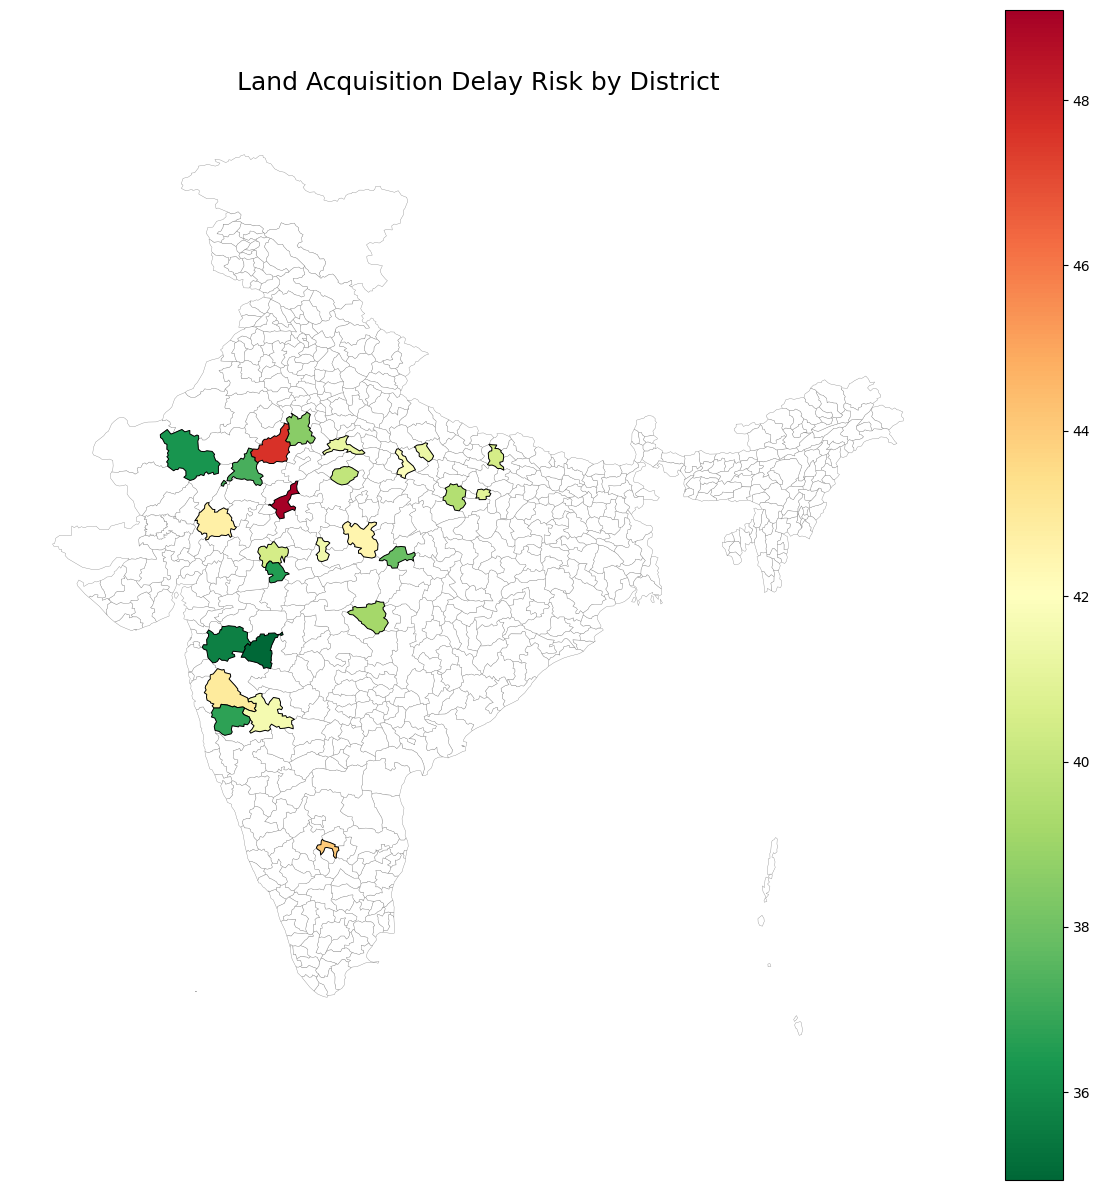

In [33]:
# Static overview: all districts in light gray, predicted districts colored
# by risk, so gaps in coverage are visible at a glance.
fig, ax = plt.subplots(figsize=(12, 12))

districts_gdf.plot(ax=ax, facecolor="white", edgecolor="gray", linewidth=0.25)
plot_data.plot(
    ax=ax, column="average_risk", cmap="RdYlGn_r", legend=True,
    edgecolor="black", linewidth=0.7,
)

ax.set_title("Land Acquisition Delay Risk by District", fontsize=18, pad=15)
ax.set_axis_off()
plt.tight_layout()
plt.show()


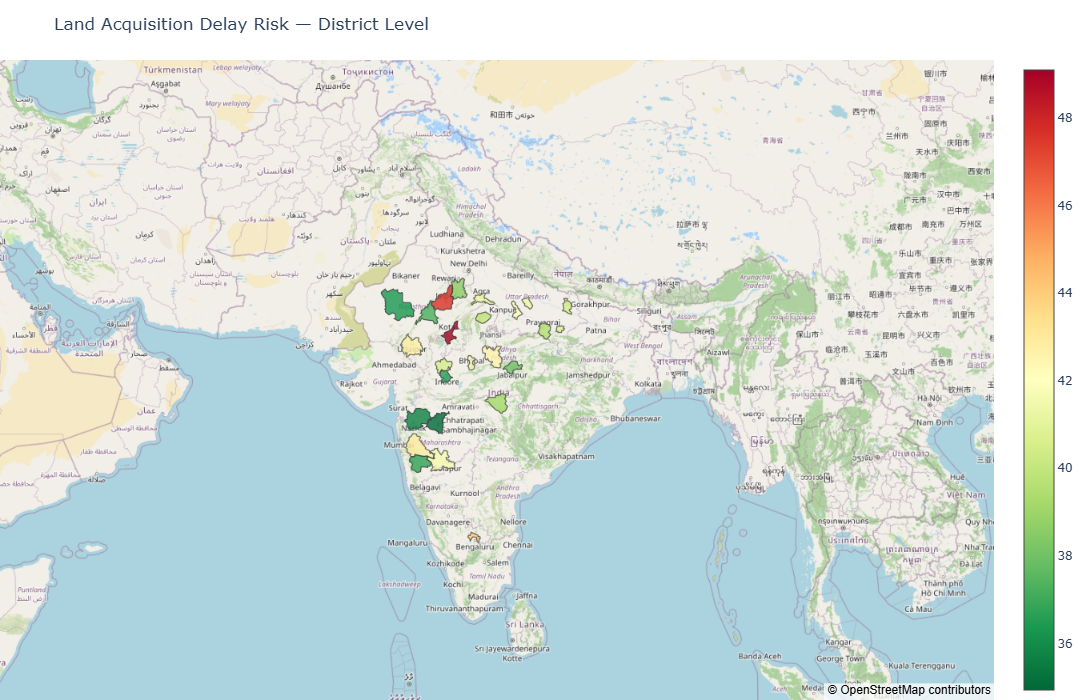

In [34]:
import plotly.graph_objects as go

# Rebuild GeoJSON restricted to the predicted districts, with the
# aggregated stats attached as properties for the hover tooltip.
predicted_features = [
    {
        "type": "Feature",
        "id": row["district"],
        "properties": {
            "district": row["district"],
            "state": row["state"],
            "total_cases": row["total_cases"],
            "high_risk_cases": row["high_risk_cases"],
            "critical_cases": row["critical_cases"],
        },
        "geometry": row["geometry"].__geo_interface__,
    }
    for _, row in plot_data.iterrows()
]
predicted_geojson = {"type": "FeatureCollection", "features": predicted_features}

fig = go.Figure(
    go.Choroplethmap(
        geojson=predicted_geojson,
        locations=plot_data["district"],
        z=plot_data["average_risk"],
        featureidkey="id",
        colorscale="RdYlGn_r",
        zmin=plot_data["average_risk"].min(),
        zmax=plot_data["average_risk"].max(),
        marker_opacity=0.8,
        marker_line_width=1,
        customdata=plot_data[
            ["state", "total_cases", "high_risk_cases", "critical_cases"]
        ].values,
        hovertemplate=(
            "<b>%{location}</b><br>"
            "State: %{customdata[0]}<br>"
            "Average Risk: %{z:.2f}%<br>"
            "Total Cases: %{customdata[1]}<br>"
            "High Risk Cases: %{customdata[2]}<br>"
            "Critical Cases: %{customdata[3]}"
            "<extra></extra>"
        ),
    )
)

fig.update_layout(
    map={"style": "open-street-map", "center": {"lat": 22.5, "lon": 79}, "zoom": 3.5},
    title="Land Acquisition Delay Risk — District Level",
    height=700,
    margin={"l": 0, "r": 0, "t": 60, "b": 0},
)
fig.show()


## 13. What-If Simulation

In [35]:
def what_if_prediction(case_X, changes, xgb_model):
    """Re-score a case after hypothetically changing some feature values."""
    modified_case = case_X.copy()
    for feature, new_value in changes.items():
        modified_case.loc[:, feature] = new_value

    probability_pct = xgb_model.predict_proba(modified_case)[0][1] * 100
    return probability_pct, categorize_risk(probability_pct), modified_case


In [36]:
# Take the highest-risk CRITICAL case as the example.
critical_cases = case_predictions[case_predictions["risk_category"] == "CRITICAL"]
selected_case = critical_cases.iloc[0]
case_X = X_test.loc[[selected_case.name]]

before_probability = selected_case["risk_probability"]
before_category = selected_case["risk_category"]

scenarios = {
    "Current Situation": {},
    "Resolve Legal Case": {"legal_case_exists": 0},
    "Complete Ownership Documents": {"missing_ownership_documents": 0},
    "Resolve Compensation Issue": {"compensation_status": "Resolved"},
    "Resolve Legal + Documents": {
        "legal_case_exists": 0, "missing_ownership_documents": 0,
    },
    "Resolve Legal + Compensation": {
        "legal_case_exists": 0, "compensation_status": "Resolved",
    },
    "Resolve All Major Issues": {
        "legal_case_exists": 0,
        "missing_ownership_documents": 0,
        "compensation_status": "Resolved",
    },
}

rows = []
for scenario_name, changes in scenarios.items():
    if scenario_name == "Current Situation":
        probability, category = before_probability, before_category
    else:
        probability, category, _ = what_if_prediction(case_X, changes, xgb_model)
    rows.append({
        "scenario": scenario_name,
        "risk_probability": probability,
        "risk_category": category,
        "risk_reduction": before_probability - probability,
    })

what_if_results = pd.DataFrame(rows).sort_values("risk_probability")
what_if_results


,scenario,risk_probability,risk_category,risk_reduction
4,Resolve Legal + Documents,91.639580,CRITICAL,5.406609
6,Resolve All Major Issues,91.639580,CRITICAL,5.406609
1,Resolve Legal Case,93.311623,CRITICAL,3.734566
5,Resolve Legal + Compensation,93.571373,CRITICAL,3.474815
2,Complete Ownership Documents,95.625389,CRITICAL,1.420799
3,Resolve Compensation Issue,96.981491,CRITICAL,0.064697
0,Current Situation,97.046188,CRITICAL,0.000000


In [37]:
best_intervention = (
    what_if_results[what_if_results["scenario"] != "Current Situation"]
    .sort_values("risk_reduction", ascending=False)
    .iloc[0]
)

print("Best intervention:", best_intervention["scenario"])
print(f"Risk after: {best_intervention['risk_probability']:.2f}% ({best_intervention['risk_category']})")
print(f"Risk reduction: {best_intervention['risk_reduction']:.2f} pp")


Best intervention: Resolve Legal + Documents
Risk after: 91.64% (CRITICAL)
Risk reduction: 5.41 pp


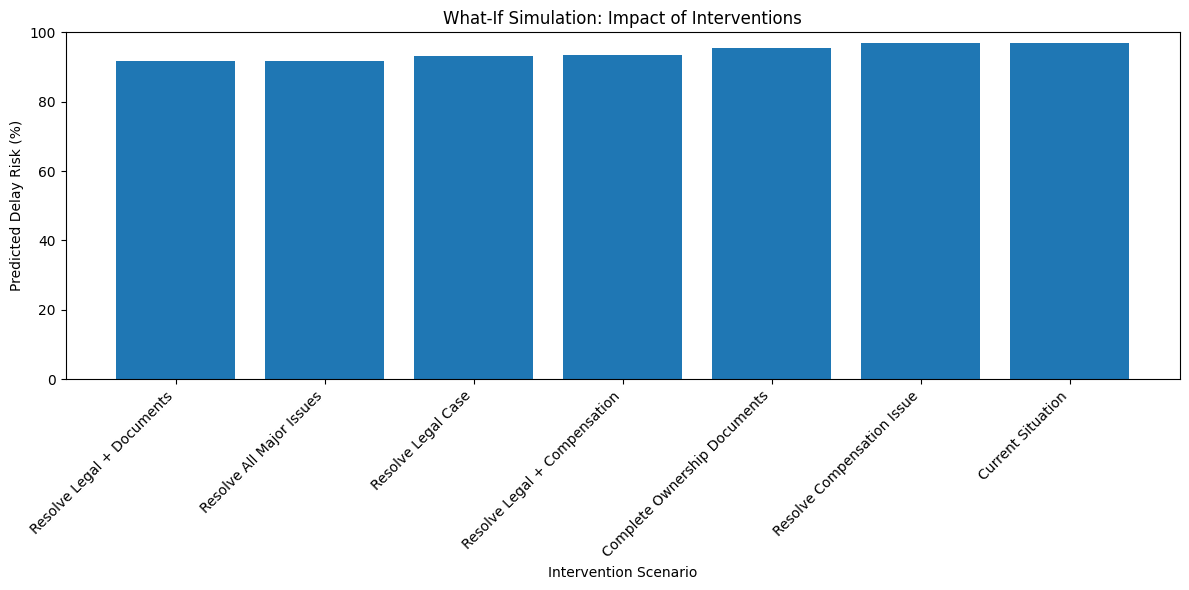

In [38]:
plt.figure(figsize=(12, 6))
plt.bar(what_if_results["scenario"], what_if_results["risk_probability"])
plt.ylabel("Predicted Delay Risk (%)")
plt.xlabel("Intervention Scenario")
plt.title("What-If Simulation: Impact of Interventions")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


## 14. Recommendations & API Output

In [39]:
RECOMMENDATION_MAP = {
    "legal_case_exists":
        "Prioritize legal-case resolution and route the case for legal review.",
    "missing_ownership_documents":
        "Verify and complete missing ownership documents before proceeding.",
    "gis_available":
        "Improve GIS/data availability and verify the parcel's spatial information.",
    "compensation_status":
        "Review the compensation case and resolve pending or disputed compensation issues.",
    "ownership_complexity":
        "Perform detailed ownership verification and resolve ownership-related complexity.",
    "ownership_dispute":
        "Prioritize resolution of ownership disputes with the concerned stakeholders.",
    "mutation_status":
        "Verify and expedite the land mutation process.",
    "pending_approval_count":
        "Follow up on pending approvals and escalate delayed approvals where necessary.",
}


def generate_recommendations(top_risk_factors):
    return [
        RECOMMENDATION_MAP[feature]
        for feature in top_risk_factors
        if feature in RECOMMENDATION_MAP
    ]


In [40]:
def predict_land_acquisition_risk(case_X, xgb_model, xgb_preprocessor,
                                   explainer, feature_names, categorical_cols):
    """Full case-level output: probability, category, drivers, actions."""
    probability_pct = xgb_model.predict_proba(case_X)[0][1] * 100
    category = categorize_risk(probability_pct)

    explanation = explain_case(
        case_X, xgb_model, xgb_preprocessor, explainer, feature_names, categorical_cols
    )
    top_risk = explanation["risk_increasing"]

    return {
        "delay_probability": round(probability_pct, 2),
        "risk_category": category,
        "top_risk_factors": top_risk[["feature", "shap_value"]].to_dict("records"),
        "recommendations": generate_recommendations(top_risk["feature"].tolist()),
    }


def create_api_output(case_X, project_id, **kwargs):
    """JSON-safe version of predict_land_acquisition_risk for an API response."""
    output = predict_land_acquisition_risk(case_X, **kwargs)
    return {
        "project_id": str(project_id),
        "delay_probability": round(float(output["delay_probability"]), 2),
        "risk_category": str(output["risk_category"]),
        "top_risk_factors": [
            {
                "feature": str(factor["feature"]),
                "shap_value": round(float(factor["shap_value"]), 4),
            }
            for factor in output["top_risk_factors"]
        ],
        "recommendations": [str(rec) for rec in output["recommendations"]],
    }


In [41]:
api_output = create_api_output(
    case_X, selected_case["project_id"],
    xgb_model=xgb_model, xgb_preprocessor=xgb_preprocessor,
    explainer=explainer, feature_names=feature_names,
    categorical_cols=categorical_cols,
)
print(json.dumps(api_output, indent=4))


{
    "project_id": "PROJ-0246",
    "delay_probability": 97.05,
    "risk_category": "CRITICAL",
    "top_risk_factors": [
        {
            "feature": "legal_case_exists",
            "shap_value": 0.8405
        },
        {
            "feature": "gis_available",
            "shap_value": 0.785
        },
        {
            "feature": "number_of_owners",
            "shap_value": 0.6111
        },
        {
            "feature": "ownership_complexity",
            "shap_value": 0.4177
        },
        {
            "feature": "missing_ownership_documents",
            "shap_value": 0.2773
        }
    ],
    "recommendations": [
        "Prioritize legal-case resolution and route the case for legal review.",
        "Improve GIS/data availability and verify the parcel's spatial information.",
        "Perform detailed ownership verification and resolve ownership-related complexity.",
        "Verify and complete missing ownership documents before proceeding."
    ]
}


## 15. Save Model Artifacts

In [42]:
joblib.dump(xgb_model, "land_acquisition_xgb_model.pkl")

model_metadata = {
    "numeric_cols": numerical_cols,
    "categorical_cols": categorical_cols,
}
with open("model_metadata.json", "w") as f:
    json.dump(model_metadata, f, indent=4)

print("Model and metadata saved.")


Model and metadata saved.


In [43]:
import json

test_payload = {
    "project_id": "PROJ-0225",
    "case_data": case_X.iloc[0].to_dict()
}

print(json.dumps(
    test_payload,
    indent=4,
    default=lambda x: x.item() if hasattr(x, "item") else str(x)
))

{
    "project_id": "PROJ-0225",
    "case_data": {
        "prediction_window_days": 45,
        "project_type": "Canal",
        "state": "Rajasthan",
        "district": "Kota",
        "tehsil": "Kishangarh",
        "required_land_area_acres": 1195.51,
        "project_age_days": 111,
        "parcel_area_acres": 14.11,
        "required_area_acres": 8.37,
        "land_use": "Agricultural",
        "ownership_type": "Joint",
        "number_of_owners": 6,
        "joint_ownership": true,
        "gis_available": false,
        "ownership_verified": 0,
        "title_clear": 0,
        "inheritance_issue": 0,
        "ownership_dispute": 0,
        "mutation_status": "Completed",
        "missing_ownership_documents": 2,
        "ownership_complexity": 65.87499999999999,
        "compensation_status": "NOT_ASSESSED",
        "assessed_amount": 0.0,
        "offered_amount": 0.0,
        "paid_amount": 0.0,
        "payment_delay_days": 0,
        "valuation_dispute": 0,
        "b

In [44]:
import json

model_metadata = {
    "feature_columns": X.columns.tolist(),
    "numeric_cols": numerical_cols,
    "categorical_cols": categorical_cols,
    "classification_threshold": float(xgb_best_threshold)
}

with open("model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(model_metadata, f, indent=4)

print("✅ Model metadata updated successfully")

✅ Model metadata updated successfully
